# 3_gridsearch_lines: dense grid search, and which lines carry the fit

A denser version of the `1_gridsearch.ipynb` grid (i = 0-90 deg in 15 deg steps, visible ff 0.05-0.50 in 0.05 steps, polar caps / equatorial band / bands at +/-30 deg: 210 models at v_eq = 4000 m/s, 430-440 nm, res3d = 5, res2d = 200), used to find which absorption lines, and which combinations of them, let a noisy spectrum pick out the right model.

**Method.** Every grid model in turn is the injected truth T; every other model N is a competitor. For white Gaussian noise with sigma = T / SNR in each bin, chi^2_N - chi^2_T over a set of bins S is Gaussian with mean Delta and variance 4 Delta, where Delta = SNR^2 * sum_S ((T - N) / T)^2. So N beats T with probability Phi(-sqrt(Delta) / 2), exactly, with no Monte Carlo. Delta is a sum over bins, so each line window contributes its own piece and line sets just add them. The per-model recovery rate uses the union bound 1 - sum_N Phi(-sqrt(Delta_N) / 2), which is checked against Monte Carlo below.

- Lines: local minima in the unbroadened quiet spectrum (`quiet_i0`, the disk-integrated SSD at i = 0) deeper than a threshold below a running-maximum pseudo-continuum. Windows run from the half-depth points, padded by the maximum rotational shift, so they contain the broadened line at any inclination. Lines are identified by wavelength only (no species).
- The four random targets from `1_gridsearch` (faculae, three band scenarios) are not grid models, so they are used last as an off-grid check: does restricting the fit to the selected lines still find the nearest (i, ff)?
- Spectra are divided by their own mean over the common bins, as in notebooks 1 and 2.

Run from `actress_highres/actress/` (all paths are relative to it).

In [1]:
import os
import sys
import time
import multiprocessing as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter1d
from scipy.signal import find_peaks, peak_widths
from scipy.special import erfc
import actress.contrasts as contrst

In [2]:
# ----- simulation setup, from 1_gridsearch.ipynb (validated there against sim_spectrum + process_disk_directory) -----
# Same LD files, wavelength grid, bins, band geometry, filling-factor solver and in-memory Doppler
# binning as 1_gridsearch, so the spectra here are directly comparable with its caches.
import time
import actress as ac
import actress.run_actress_notebook as actr

grid_phot_file = './inputs/limb_files/average_intensities_ssd_driftcorrected.txt'   # real SSD, with lines
grid_fac_file = './inputs/limb_files/average_intensities_200G_driftcorrected.txt'
grid_phot_ld_file = 'test_phot_ssd_4300_4400.txt'
grid_fac_ld_file = 'test_fac_200G_4300_4400.txt'
grid_ld_law = 'power2'
# The files span 430.00034-440.00055 nm. contrast() takes delta_freq from both neighbours of
# each kept sample, so the two end samples cannot be used; start and stop one sample inside.
grid_wav_lower = 4.3001e-7   # m
grid_wav_higher = 4.3999e-7  # m

grid_v_eq = 4000                  # m/s, equatorial rotation velocity, fixed for every run
grid_res3d = 5                    # healpix nside = 2^5
grid_res2d = 200                  # pixels across the projected disk
# At nside 32 the visible ff moves in steps of up to ~0.026 (one healpix ring), so the target
# can only be hit to about half a step. Anything further off means the solver failed.
grid_ff_tolerance = 0.02
grid_n_workers = 8                # processes; this runs on a shared login node

# ----- limb-darkening fits over 430-440 nm, every native sample -----
grid_file_wav_nm = pd.read_csv(grid_phot_file, sep=r'\s+', comment='#').values[:, 0]   # nm
grid_log_grid_wav = contrst.wav_nm_to_m(contrst.log_uniform_grid(grid_file_wav_nm, R=500000))   # m, the grid contrast() uses
grid_indx_low, grid_indx_high = contrst.wav_limits(list(grid_log_grid_wav), grid_wav_lower, grid_wav_higher)
if grid_indx_low < 1 or grid_indx_high > len(grid_log_grid_wav) - 2:
    raise ValueError(f"Window indices {grid_indx_low}-{grid_indx_high} leave no neighbour for delta_freq")
# N such that contrast()'s step round((high - low) / N) is 1: every 0.0087 A (~600 m/s) sample is
# kept, rather than every 2nd as in the 4376 cells, so the 4000 m/s broadening spans ~13 bins.
grid_N_ld = grid_indx_high - grid_indx_low

contrst.validate_inputs(grid_fac_file, grid_phot_file, grid_wav_lower, grid_wav_higher, graphs=False)
for source_file, ld_file in ((grid_phot_file, grid_phot_ld_file), (grid_fac_file, grid_fac_ld_file)):
    if os.path.exists(ld_file):
        print(f"Using existing {ld_file}")
        continue
    t_start = time.time()
    contrst.contrast(source_file, wav_lower=grid_wav_lower, wav_higher=grid_wav_higher, N=grid_N_ld,
                     ld_law=grid_ld_law, save=ld_file, graphs=False)
    print(f"Wrote {ld_file} ({time.time() - t_start:.0f} s)")
contrst.validate_outputs(grid_fac_ld_file, grid_phot_ld_file, graphs=False)

grid_phot_ld = np.loadtxt(grid_phot_ld_file)   # columns: wavelength (m), I0, c1, c2
grid_fac_ld = np.loadtxt(grid_fac_ld_file)
if len(grid_phot_ld) != grid_indx_high - grid_indx_low + 1:
    raise ValueError(f"{grid_phot_ld_file} has {len(grid_phot_ld)} rows, expected every sample "
                     f"{grid_indx_low}-{grid_indx_high}; it was made with different settings")

# Wavelength labels exactly as run_actress_notebook formats them, and the bins
# process_disk_directory builds from them: centres are the sampled wavelengths themselves.
grid_wavelength_texts = [f"{wav * 1e10:.4f}" for wav in grid_phot_ld[:, 0]]
grid_input_wavelengths = np.array([float(text) for text in grid_wavelength_texts])   # Angstrom
grid_midpoints = 0.5 * (grid_input_wavelengths[:-1] + grid_input_wavelengths[1:])
grid_bin_edges = np.concatenate((
    [grid_input_wavelengths[0] - (grid_input_wavelengths[1] - grid_input_wavelengths[0]) / 2],
    grid_midpoints,
    [grid_input_wavelengths[-1] + (grid_input_wavelengths[-1] - grid_input_wavelengths[-2]) / 2]))
grid_bin_edges_rounded = np.round(grid_bin_edges, 10)

# Images are shown where the facula is brightest relative to the photosphere at disk centre.
grid_image_index = int(np.argmax(grid_fac_ld[:, 1] / grid_phot_ld[:, 1]))
print(f"{len(grid_input_wavelengths)} wavelengths, {grid_input_wavelengths[0]:.4f}-{grid_input_wavelengths[-1]:.4f} A; "
      f"images at {grid_input_wavelengths[grid_image_index]:.4f} A "
      f"(I0_fac / I0_phot = {grid_fac_ld[grid_image_index, 1] / grid_phot_ld[grid_image_index, 1]:.3f})")

_grid_ld_params = actr.Transitparams()
_grid_ld_params.ld = grid_ld_law
grid_ld_func = actr.Transitsim(_grid_ld_params).ld_law   # the same law function sim_spectrum passes to actress


# ----- geometry -----
def band_strips(geometry, half_width):
    """(lower, upper) addstrip latitudes in deg for a band family of half-width `half_width` (deg)."""
    if geometry == 'polar_caps':
        return [(-90, -90 + half_width), (90 - half_width, 90)]
    if geometry == 'equatorial':
        return [(-half_width, half_width)]
    if geometry == 'bands_pm30':
        return [(30 - half_width, 30 + half_width), (-30 - half_width, -30 + half_width)]
    raise ValueError(f"Unknown geometry {geometry}")

# Beyond these half-widths a band edge passes a pole and addstrip reflects it back silently.
grid_max_half_width = {'polar_caps': 90, 'equatorial': 90, 'bands_pm30': 60}   # deg


def build_grid_simulator(strips, faculae):
    """actress Simulator with the given strips [(lower, upper)] and faculae [(r, lon, lat)], deg."""
    sim = ac.Simulator(faculae=[], spots=[], fac_strips=[], spot_strips=[])   # explicit lists: the defaults are shared between instances
    sim.setxsize(grid_res2d)
    sim.setresolution(grid_res3d)
    for lower, upper in strips:
        if lower < -90 or upper > 90:
            raise ValueError(f"Strip ({lower}, {upper}) leaves +/-90 deg and would be reflected by addstrip")
        sim.addstrip(lower=lower, upper=upper, feature='fac')
    for r, lon, lat in faculae:
        sim.addfeature(r=r, lon=lon, lat=lat, feature='fac')
    return sim


def visible_fill(strips, faculae, inc):
    return build_grid_simulator(strips, faculae).getdiscfill(feature='fac', inc=inc)


def solve_half_width(geometry, inc, target_ff):
    """Half-width (deg) whose visible ff is closest to target_ff, by bisection (ff grows with width)."""
    lower, upper = 0.0, float(grid_max_half_width[geometry])
    if visible_fill(band_strips(geometry, upper), [], inc) < target_ff:
        raise ValueError(f"{geometry} at i = {inc} cannot reach visible ff {target_ff}")
    for _ in range(40):
        middle = (lower + upper) / 2
        if visible_fill(band_strips(geometry, middle), [], inc) < target_ff:
            lower = middle
        else:
            upper = middle
    # ff is a step function of width (whole healpix pixels), so take the closer side of the step.
    ff_lower = visible_fill(band_strips(geometry, lower), [], inc)
    ff_upper = visible_fill(band_strips(geometry, upper), [], inc)
    if abs(ff_lower - target_ff) < abs(ff_upper - target_ff):
        half_width, ff = lower, ff_lower
    else:
        half_width, ff = upper, ff_upper
    if abs(ff - target_ff) > grid_ff_tolerance:
        raise ValueError(f"{geometry} at i = {inc}: closest visible ff {ff:.4f} misses target {target_ff}")
    return half_width, ff


# ----- spectrum of one run, binned as process_disk_directory does -----
def set_grid_ld(sim, k):
    """Limb-darkening dict for wavelength row k, built as Transitsim.actress_run builds it."""
    sim.setld({'phot': [grid_phot_ld[k, 1], grid_phot_ld[k, 2], grid_phot_ld[k, 3], None, None],
               'spot': [12955331.717385203, 0.3, 0.2, 0.1, 0.1],   # unused in faconly mode
               'fac': [grid_fac_ld[k, 1], grid_fac_ld[k, 2], grid_fac_ld[k, 3], None, None],
               'func': grid_ld_func})


def simulate_grid_spectrum(run):
    """
    Disk-integrated spectrum at rotation angle 0 for one run.

    Returns (bin_centers (A), mean intensity per bin, disk image at grid_image_index).
    Same steps as disk_utils.process_disk_directory: shift each on-disk pixel by its Doppler
    shift, drop points within max_shift of the window ends, bin to the input wavelengths
    (edges rounded to 1e-10 A), keep only bins fully inside the trimmed range, average.
    """
    sim = build_grid_simulator(run['strips'], run['faculae'])
    n_bins = len(grid_input_wavelengths)
    # The shift map is -lambda v_los / c, so its maximum is at the longest wavelength; it is
    # needed before the loop to trim points exactly as process_disk_directory does.
    set_grid_ld(sim, n_bins - 1)
    _, shift_longest = sim.rotate_lc(v_eq=grid_v_eq, inc=run['inc'], N=1, mode='faconly',
                                     wavelength=grid_wavelength_texts[-1], returndisc=True)
    max_shift = shift_longest.max()   # A
    trim_lower = grid_input_wavelengths.min() + max_shift
    trim_upper = grid_input_wavelengths.max() - max_shift

    sums = np.zeros(n_bins)
    counts = np.zeros(n_bins, dtype=np.int64)
    largest_shift_seen = -np.inf
    image = None
    for k, wavelength_text in enumerate(grid_wavelength_texts):
        set_grid_ld(sim, k)
        disks, shift = sim.rotate_lc(v_eq=grid_v_eq, inc=run['inc'], N=1, mode='faconly',
                                     wavelength=wavelength_text, returndisc=True)
        disk = disks[0]
        largest_shift_seen = max(largest_shift_seen, shift.max())
        on_disk = disk > 0   # rotate_lc sets the off-disk background to 0
        observed_wavelength = grid_input_wavelengths[k] + shift[on_disk]
        intensity = disk[on_disk]
        kept = (observed_wavelength >= trim_lower) & (observed_wavelength <= trim_upper)
        point_bins = np.searchsorted(grid_bin_edges_rounded, np.round(observed_wavelength[kept], 10), side='right') - 1
        in_range = (point_bins >= 0) & (point_bins < n_bins)
        sums += np.bincount(point_bins[in_range], weights=intensity[kept][in_range], minlength=n_bins)
        counts += np.bincount(point_bins[in_range], minlength=n_bins)
        if k == grid_image_index:
            image = disk.copy()

    if largest_shift_seen != max_shift:
        raise ValueError(f"{run['name']}: max shift {largest_shift_seen} is not at the longest wavelength ({max_shift})")
    valid_bins = (grid_bin_edges[:-1] >= trim_lower) & (grid_bin_edges[1:] <= trim_upper)
    if np.any(counts[valid_bins] == 0):
        raise ValueError(f"{run['name']}: {np.sum(counts[valid_bins] == 0)} empty wavelength bins")
    return grid_input_wavelengths[valid_bins], sums[valid_bins] / counts[valid_bins], image



Using existing test_phot_ssd_4300_4400.txt
Using existing test_fac_200G_4300_4400.txt
11473 wavelengths, 4300.0980-4399.8999 A; images at 4384.7640 A (I0_fac / I0_phot = 2.245)


In [3]:
# ----- dense grid: simulate, or load the cache -----
dense_incs = [0, 15, 30, 45, 60, 75, 90]                                   # deg
dense_target_ffs = [round(0.05 * k, 2) for k in range(1, 11)]              # visible-disk ff, 0.05-0.50
dense_geometries = ['polar_caps', 'equatorial', 'bands_pm30']
dense_cache_file = (f'./outputs/gridsearch/3_gridsearch_dense_v{grid_v_eq}_res3d{grid_res3d}_res2d{grid_res2d}'
                    f'_{grid_wav_lower * 1e10:.1f}_{grid_wav_higher * 1e10:.1f}_i15_ff005.npz')

dense_runs = []
for geometry in dense_geometries:
    for inc in dense_incs:
        for target_ff in dense_target_ffs:
            half_width, ff = solve_half_width(geometry, inc, target_ff)
            dense_runs.append({'name': f'{geometry}_ff{target_ff:.2f}_i{inc}', 'geometry': geometry, 'inc': inc,
                               'target_ff': target_ff, 'visible_ff': ff, 'half_width': half_width,
                               'strips': band_strips(geometry, half_width), 'faculae': []})
ff_errors = [abs(run['visible_ff'] - run['target_ff']) for run in dense_runs]
print(f"{len(dense_runs)} models; |visible ff - target| max {max(ff_errors):.4f}, median {np.median(ff_errors):.4f}")

dense_run_names = np.array([run['name'] for run in dense_runs])
dense_config = np.array([grid_v_eq, grid_res3d, grid_res2d, len(grid_input_wavelengths)], dtype=float)
dense_half_widths = np.array([run['half_width'] for run in dense_runs])
dense_spectra = {}
if os.path.exists(dense_cache_file):
    cached = np.load(dense_cache_file)
    if not (np.array_equal(cached['run_names'], dense_run_names) and np.array_equal(cached['config'], dense_config)
            and np.allclose(cached['half_widths'], dense_half_widths)):
        raise ValueError(f"{dense_cache_file} was made with different runs or settings. "
                         "Delete or rename it by hand if it should be replaced.")
    for name in dense_run_names:
        dense_spectra[name] = (cached[f'bins_{name}'], cached[f'spectrum_{name}'])
    print(f"Loaded {len(dense_spectra)} spectra from {dense_cache_file}")
else:
    t_start = time.time()
    ctx = mp.get_context('fork')
    with ctx.Pool(processes=grid_n_workers) as pool:
        results = pool.map(simulate_grid_spectrum, dense_runs, chunksize=1)
    for run, (bins, spectrum, image) in zip(dense_runs, results):
        dense_spectra[run['name']] = (bins, spectrum)   # images are not kept: 210 x 320 kB for no analysis use
    print(f"Simulated {len(dense_runs)} runs x {len(grid_input_wavelengths)} wavelengths in {(time.time() - t_start) / 60:.1f} min")
    os.makedirs(os.path.dirname(dense_cache_file), exist_ok=True)
    to_save = {'run_names': dense_run_names, 'config': dense_config, 'half_widths': dense_half_widths,
               'visible_ffs': np.array([run['visible_ff'] for run in dense_runs])}
    for name, (bins, spectrum) in dense_spectra.items():
        to_save[f'bins_{name}'] = bins
        to_save[f'spectrum_{name}'] = spectrum
    np.savez(dense_cache_file, **to_save)
    print(f"Wrote {dense_cache_file}")

for name, (bins, spectrum) in dense_spectra.items():
    if not np.all(np.isfinite(spectrum)) or np.any(spectrum <= 0):
        raise ValueError(f"{name}: non-finite or non-positive intensity in the spectrum")

210 models; |visible ff - target| max 0.0130, median 0.0044


/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/run_actress_notebook.py:63: RuntimeWarning: divide by zero encountered in power
  y = I0 * (1-(a*(1-(mu**b))))


/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/run_actress_notebook.py:63: RuntimeWarning: divide by zero encountered in power
  y = I0 * (1-(a*(1-(mu**b))))


/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/run_actress_notebook.py:63: RuntimeWarning: divide by zero encountered in power
  y = I0 * (1-(a*(1-(mu**b))))


/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/run_actress_notebook.py:63: RuntimeWarning: divide by zero encountered in power
  y = I0 * (1-(a*(1-(mu**b))))


...

/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/run_actress_notebook.py:63: RuntimeWarning: divide by zero encountered in power
  y = I0 * (1-(a*(1-(mu**b))))


/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/run_actress_notebook.py:63: RuntimeWarning: divide by zero encountered in power
  y = I0 * (1-(a*(1-(mu**b))))


/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/run_actress_notebook.py:63: RuntimeWarning: divide by zero encountered in power
  y = I0 * (1-(a*(1-(mu**b))))


Simulated 210 runs x 11473 wavelengths in 148.2 min


Wrote ./outputs/gridsearch/3_gridsearch_dense_v4000_res3d5_res2d200_4300.1_4399.9_i15_ff005.npz


In [4]:
# ----- targets from 1_gridsearch, common bins, normalised model matrix -----
grid_cache = np.load('./outputs/gridsearch/1_gridsearch_v4000_res3d5_res2d200_4300.1_4399.9_randomseed0.npz')
band_cache = np.load('./outputs/gridsearch/1_gridsearch_randombands_v4000_res3d5_res2d200_4300.1_4399.9_seeds1-3.npz')

offgrid_targets = {'random': {'inc': grid_cache['config'][6],
                              'visible_ff': grid_cache['visible_ffs'][list(grid_cache['run_names']).index('random')],
                              'spectrum': (grid_cache['bins_random'], grid_cache['spectrum_random'])}}
for k, name in enumerate(band_cache['run_names']):
    if name.startswith('random_bands'):
        offgrid_targets[name] = {'inc': band_cache['incs'][k], 'visible_ff': band_cache['visible_ffs'][k],
                                 'spectrum': (band_cache[f'bins_{name}'], band_cache[f'spectrum_{name}'])}
quiet_bins, quiet_spectrum = grid_cache['bins_quiet_i0'], grid_cache['spectrum_quiet_i0']

# Common bins: left after the i = 90 edge trimming in every spectrum used.
common_bins = quiet_bins
for bins, _ in list(dense_spectra.values()) + [target['spectrum'] for target in offgrid_targets.values()]:
    common_bins = np.intersect1d(common_bins, bins)


def on_common_bins(bins, spectrum, label):
    on_common = np.isin(bins, common_bins)
    if on_common.sum() != len(common_bins):
        raise ValueError(f"{label} does not cover all common bins")
    return spectrum[on_common]


model_names = list(dense_run_names)
model_inc = np.array([run['inc'] for run in dense_runs], dtype=float)
model_ff = np.array([run['visible_ff'] for run in dense_runs])
model_geometry = np.array([run['geometry'] for run in dense_runs])
model_matrix = np.array([on_common_bins(*dense_spectra[name], name) for name in model_names])
model_matrix = model_matrix / model_matrix.mean(axis=1, keepdims=True)   # (n_models, n_bins), each / its own mean
n_models, n_bins = model_matrix.shape
print(f"{n_models} models, {n_bins} common bins, {common_bins[0]:.4f}-{common_bins[-1]:.4f} A")

210 models, 11457 common bins, 4300.1668-4399.8295 A


354 lines deeper than 0.05 below the 2.0 A running maximum; windows padded by 7 bins (0.0587 A); they cover 77.9% of the 11457 bins


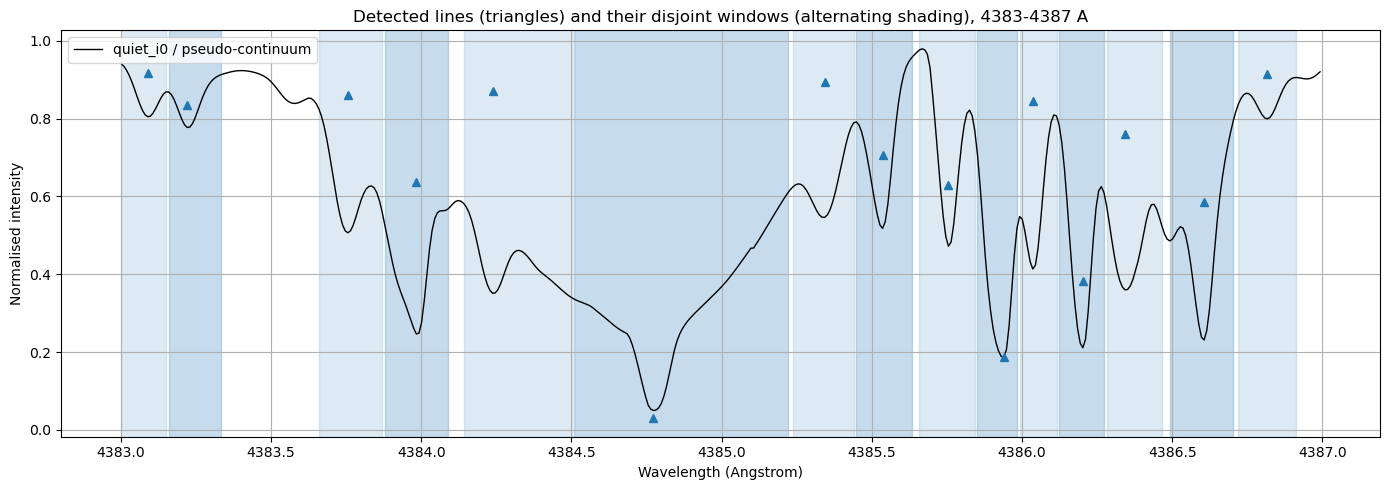

In [5]:
# ----- absorption lines in the unbroadened quiet spectrum -----
# Pseudo-continuum: running maximum over 2 A. 430-440 nm has no truly line-free stretch, so depths
# are relative to the local maximum, not to a true continuum.
continuum_window = 2.0     # A
line_min_depth = 0.05      # minimum prominence, as a fraction of the pseudo-continuum
bin_width = np.median(np.diff(common_bins))                  # A, ~0.0087
max_rotational_shift = grid_v_eq / 3e8 * common_bins.max()   # A, with the c simulator.rotate_lc uses
pad_bins = int(np.ceil(max_rotational_shift / bin_width))

quiet_common = on_common_bins(quiet_bins, quiet_spectrum, 'quiet_i0')
pseudo_continuum = maximum_filter1d(quiet_common, size=int(round(continuum_window / bin_width)), mode='nearest')
depth = 1 - quiet_common / pseudo_continuum
line_centres, properties = find_peaks(depth, prominence=line_min_depth)
line_wavelengths = common_bins[line_centres]
line_depths = properties['prominences']
n_lines = len(line_centres)

# Window: half-depth points (measured from each line's prominence base), padded by the largest
# Doppler shift so the broadened line fits at any inclination. Where windows of neighbouring lines
# overlap, the shared bins go to the nearer line centre, so windows are disjoint and each bin's
# chi^2 is counted once: per-line Delta then adds up exactly for any combination of lines.
_, _, left_half, right_half = peak_widths(depth, line_centres, rel_height=0.5)
line_left = np.maximum(np.floor(left_half).astype(int) - pad_bins, 0)
line_right = np.minimum(np.ceil(right_half).astype(int) + pad_bins, n_bins - 1)   # inclusive
for l in range(n_lines - 1):
    if line_right[l] >= line_left[l + 1]:
        split = (line_centres[l] + line_centres[l + 1]) // 2
        line_right[l] = split
        line_left[l + 1] = split + 1
if np.any(line_left > line_centres) or np.any(line_right < line_centres):
    raise ValueError("Splitting overlapping windows pushed a window off its own line centre")

in_any_line = np.zeros(n_bins, dtype=bool)
for left, right in zip(line_left, line_right):
    in_any_line[left:right + 1] = True
print(f"{n_lines} lines deeper than {line_min_depth} below the {continuum_window} A running maximum; windows padded by "
      f"{pad_bins} bins ({max_rotational_shift:.4f} A); they cover {in_any_line.mean() * 100:.1f}% of the {n_bins} bins")

fig, ax = plt.subplots(figsize=(14, 5))
zoom = (common_bins >= 4383) & (common_bins <= 4387)
ax.plot(common_bins[zoom], quiet_common[zoom] / pseudo_continuum[zoom], color='k', linewidth=1, label='quiet_i0 / pseudo-continuum')
for k in np.where((line_wavelengths >= 4383) & (line_wavelengths <= 4387))[0]:
    ax.axvspan(common_bins[line_left[k]], common_bins[line_right[k]], color='tab:blue', alpha=0.15 + 0.1 * (k % 2))
    ax.plot(line_wavelengths[k], 1 - line_depths[k] - 0.02, marker='^', color='tab:blue')
ax.set_xlabel('Wavelength (Angstrom)')
ax.set_ylabel('Normalised intensity')
ax.set_title('Detected lines (triangles) and their disjoint windows (alternating shading), 4383-4387 A')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

Lines carry 99.0% (median over pairs) of the full-spectrum separation, from 77.9% of the bins

Hardest competitor, full spectrum: how often it differs from the truth in only one parameter
  only ff differs: 0.23, only i differs: 0.00, only geometry differs: 0.36

Top 20 lines by median share of the hardest-pair separation (354 lines in total):
rank  lambda (A)  depth            window (A)  median share
   1   4384.7727  0.950  4384.5096- 4385.2200        0.0701
   2   4326.9712  0.953  4326.7722- 4327.3780        0.0632
   3   4309.1118  0.954  4309.0429- 4309.4307        0.0528
   4   4377.1586  0.940  4377.0098- 4377.3162        0.0277
   5   4300.4420  0.448  4300.3044- 4300.5624        0.0252
   6   4338.2620  0.900  4338.1665- 4338.3574        0.0163
   7   4301.2506  0.715  4301.1560- 4301.3710        0.0156
   8   4316.2968  0.909  4316.2450- 4316.4349        0.0140
   9   4303.7374  0.885  4303.5739- 4303.8321        0.0135
  10   4396.2583  0.898  4396.1880- 4396.3550        0

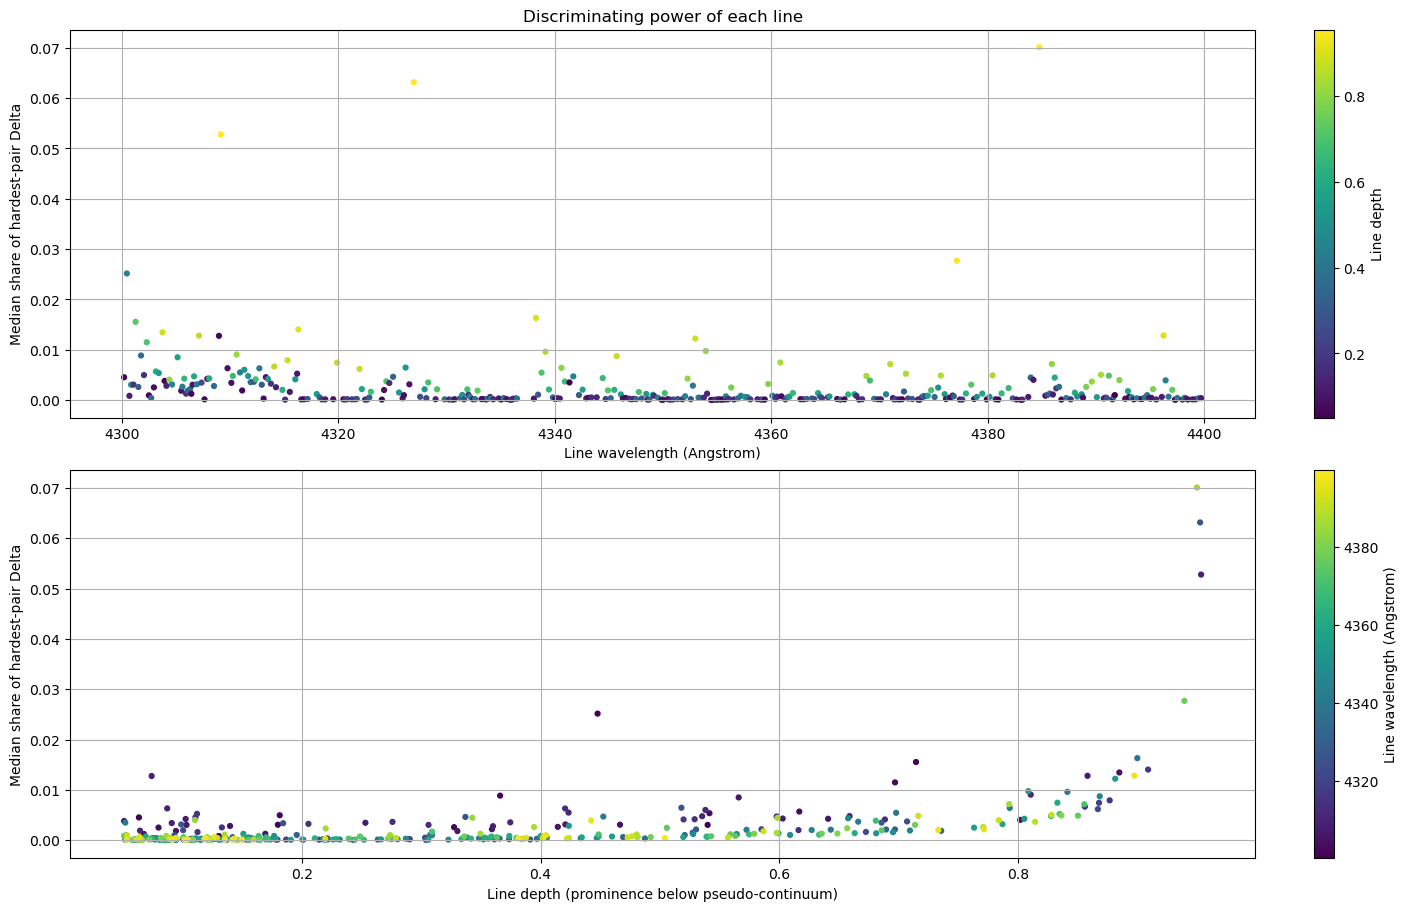

In [6]:
# ----- per-line discrimination between every pair of models -----
# line_delta[t, n, l] = sum over line l's window of ((T - N) / T)^2 for truth t and competitor n:
# the expected chi^2 separation at SNR = 1 (it scales as SNR^2). Window sums via cumulative sums.
line_delta = np.zeros((n_models, n_models, n_lines))
full_delta = np.zeros((n_models, n_models))   # every common bin, lines or not
for t in range(n_models):
    relative_difference_sq = ((model_matrix - model_matrix[t]) / model_matrix[t]) ** 2   # (n_models, n_bins)
    cumulative = np.concatenate((np.zeros((n_models, 1)), np.cumsum(relative_difference_sq, axis=1)), axis=1)
    line_delta[t] = cumulative[:, line_right + 1] - cumulative[:, line_left]
    full_delta[t] = cumulative[:, -1]
all_lines_delta = np.sum(line_delta, axis=2)   # exact for the union, since windows are disjoint
is_self = np.eye(n_models, dtype=bool)
full_delta[is_self] = np.inf
all_lines_delta[is_self] = np.inf
line_delta[is_self] = np.inf   # a model never competes with itself

# Hardest competitor of each model over the full spectrum, and each line's share of that separation.
hardest = np.argmin(full_delta, axis=1)
hardest_full = full_delta[np.arange(n_models), hardest]
share_of_hardest = line_delta[np.arange(n_models), hardest, :] / hardest_full[:, None]
line_score = np.median(share_of_hardest, axis=0)   # median over the 210 truths

print(f"Lines carry {np.median(all_lines_delta[~is_self] / full_delta[~is_self]) * 100:.1f}% (median over pairs) "
      f"of the full-spectrum separation, from {in_any_line.mean() * 100:.1f}% of the bins")
print("\nHardest competitor, full spectrum: how often it differs from the truth in only one parameter")
same_geometry = model_geometry[hardest] == model_geometry
same_inc = model_inc[hardest] == model_inc
same_ff = np.isclose([dense_runs[k]['target_ff'] for k in hardest], [run['target_ff'] for run in dense_runs])
print(f"  only ff differs: {np.mean(same_geometry & same_inc):.2f}, only i differs: {np.mean(same_geometry & same_ff):.2f}, "
      f"only geometry differs: {np.mean(same_inc & same_ff):.2f}")

order = np.argsort(line_score)[::-1]
print(f"\nTop 20 lines by median share of the hardest-pair separation ({n_lines} lines in total):")
print(f"{'rank':>4s} {'lambda (A)':>11s} {'depth':>6s} {'window (A)':>21s} {'median share':>13s}")
for rank, l in enumerate(order[:20], start=1):
    print(f"{rank:4d} {line_wavelengths[l]:11.4f} {line_depths[l]:6.3f} "
          f"{common_bins[line_left[l]]:10.4f}-{common_bins[line_right[l]]:10.4f} {line_score[l]:13.4f}")

fig, axes = plt.subplots(2, 1, figsize=(14, 9), constrained_layout=True)
sc = axes[0].scatter(line_wavelengths, line_score, s=12, c=line_depths, cmap='viridis')
fig.colorbar(sc, ax=axes[0], label='Line depth')
axes[0].set_xlabel('Line wavelength (Angstrom)')
axes[0].set_ylabel('Median share of hardest-pair Delta')
axes[0].set_title('Discriminating power of each line')
axes[0].grid(True)
sc = axes[1].scatter(line_depths, line_score, s=12, c=line_wavelengths, cmap='viridis')
fig.colorbar(sc, ax=axes[1], label='Line wavelength (Angstrom)')
axes[1].set_xlabel('Line depth (prominence below pseudo-continuum)')
axes[1].set_ylabel('Median share of hardest-pair Delta')
axes[1].grid(True)
plt.show()


SNR 1000: mean recovery with all bins 1.000, all 354 lines 1.000, greedy 1 / 5 / 10 / 25 lines 1.000 / 1.000 / 1.000 / 1.000
  step  lambda (A)  depth score rank  mean recovery
     1   4384.7727  0.950          1          1.000
     2   4326.9712  0.953          2          1.000
     3   4309.1118  0.954          3          1.000
     4   4396.2583  0.898         10          1.000
     5   4377.1586  0.940          4          1.000
     6   4301.2506  0.715          7          1.000
     7   4300.4420  0.448          5          1.000
     8   4338.2620  0.900          6          1.000
     9   4339.1297  0.842         16          1.000
    10   4316.2968  0.909          8          1.000

SNR 300: mean recovery with all bins 1.000, all 354 lines 1.000, greedy 1 / 5 / 10 / 25 lines 0.992 / 0.998 / 0.999 / 1.000
  step  lambda (A)  depth score rank  mean recovery
     1   4384.7727  0.950          1          0.992
     2   4326.9712  0.953          2          0.996
     3   4309.1118  0

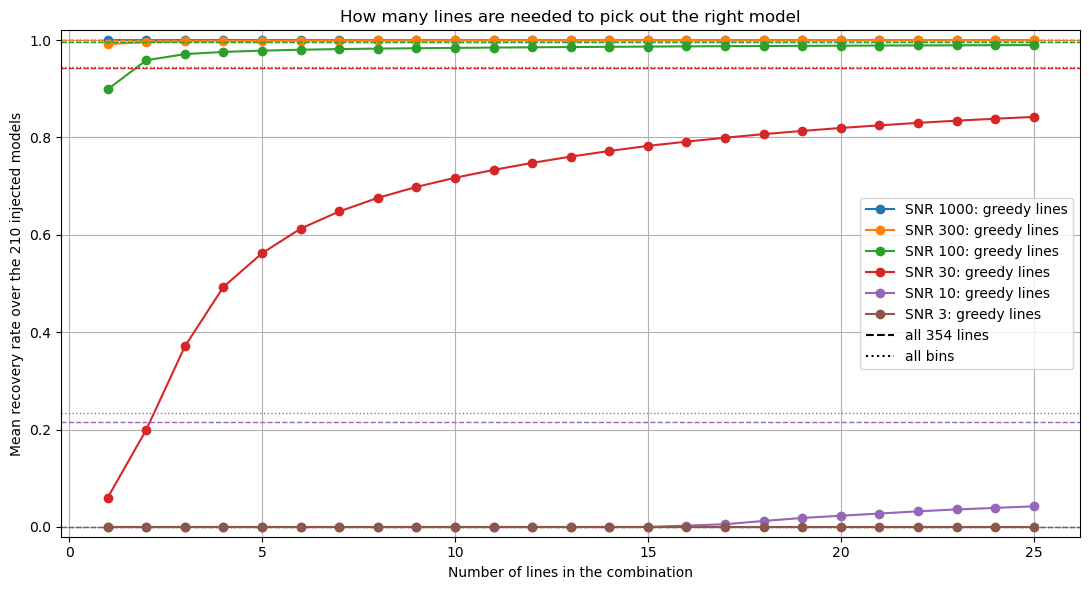

SNR 1000, all bins: least recoverable models: bands_pm30_ff0.05_i90 (1.00, vs equatorial_ff0.05_i90), bands_pm30_ff0.10_i90 (1.00, vs equatorial_ff0.10_i90), bands_pm30_ff0.15_i90 (1.00, vs equatorial_ff0.15_i90), bands_pm30_ff0.20_i90 (1.00, vs equatorial_ff0.20_i90), bands_pm30_ff0.25_i90 (1.00, vs equatorial_ff0.20_i90)
SNR 300, all bins: least recoverable models: bands_pm30_ff0.05_i75 (1.00, vs equatorial_ff0.05_i75), equatorial_ff0.05_i75 (1.00, vs bands_pm30_ff0.05_i75), equatorial_ff0.05_i90 (1.00, vs bands_pm30_ff0.05_i90), bands_pm30_ff0.05_i90 (1.00, vs equatorial_ff0.05_i90), bands_pm30_ff0.10_i60 (1.00, vs equatorial_ff0.10_i60)
SNR 100, all bins: least recoverable models: bands_pm30_ff0.05_i75 (0.89, vs equatorial_ff0.05_i75), equatorial_ff0.05_i75 (0.89, vs bands_pm30_ff0.05_i75), equatorial_ff0.05_i90 (0.89, vs bands_pm30_ff0.05_i90), bands_pm30_ff0.05_i90 (0.89, vs equatorial_ff0.05_i90), bands_pm30_ff0.10_i60 (0.92, vs equatorial_ff0.10_i60)
SNR 30, all bins: least rec

In [7]:
# ----- greedy line combinations -----
# Recovery of truth t with line set S at SNR s: 1 - sum_n Phi(-s sqrt(Delta_S(t, n)) / 2), clipped
# at 0 (union bound over competitors). Greedy: add, one at a time, the line that most raises the mean
# recovery over all 210 truths. Repeated per SNR, because which separations matter depends on noise.
# 1000-100 covers HARPS-N (solar telescope ~250-460 per pixel at 550 nm, night-time 50-200);
# 30-3 is where the breakdown sweep in 2_gridsearch_noise loses the best fit.
snr_levels = [1000, 300, 100, 30, 10, 3]   # per 0.0087 A bin
n_greedy = 25


def recovery_rate(delta, snr):
    # Per-truth recovery (n_truths,) from Delta at SNR 1, shape (n_truths, n_competitors).
    fail = 0.5 * erfc(snr * np.sqrt(delta) / (2 * np.sqrt(2)))   # Phi(-x) = erfc(x / sqrt 2) / 2; 0 on the diagonal (inf)
    return np.clip(1 - np.sum(fail, axis=1), 0, 1)


greedy = {}
for snr in snr_levels:
    delta_selected = np.where(is_self, np.inf, 0.0)
    chosen = []
    mean_recovery = []
    for step in range(n_greedy):
        best_line, best_value = None, -1.0
        for l in range(n_lines):
            if l in chosen:
                continue
            value = np.mean(recovery_rate(delta_selected + line_delta[:, :, l], snr))
            if value > best_value:
                best_line, best_value = l, value
        chosen.append(best_line)
        delta_selected = delta_selected + line_delta[:, :, best_line]
        mean_recovery.append(best_value)
    greedy[snr] = {'lines': chosen, 'mean_recovery': np.array(mean_recovery),
                   'per_truth': recovery_rate(delta_selected, snr),
                   'all_lines': np.mean(recovery_rate(all_lines_delta, snr)),
                   'full': np.mean(recovery_rate(full_delta, snr))}

for snr in snr_levels:
    g = greedy[snr]
    print(f"\nSNR {snr}: mean recovery with all bins {g['full']:.3f}, all {n_lines} lines {g['all_lines']:.3f}, "
          f"greedy 1 / 5 / 10 / {n_greedy} lines {g['mean_recovery'][0]:.3f} / {g['mean_recovery'][4]:.3f} / "
          f"{g['mean_recovery'][9]:.3f} / {g['mean_recovery'][-1]:.3f}")
    print(f"  {'step':>4s} {'lambda (A)':>11s} {'depth':>6s} {'score rank':>10s} {'mean recovery':>14s}")
    for step, l in enumerate(g['lines'][:10], start=1):
        print(f"  {step:4d} {line_wavelengths[l]:11.4f} {line_depths[l]:6.3f} {int(np.where(order == l)[0][0]) + 1:10d} "
              f"{g['mean_recovery'][step - 1]:14.3f}")

fig, ax = plt.subplots(figsize=(11, 6))
for k, snr in enumerate(snr_levels):
    colour = f'C{k}'
    g = greedy[snr]
    ax.plot(np.arange(1, n_greedy + 1), g['mean_recovery'], marker='o', color=colour, label=f'SNR {snr}: greedy lines')
    ax.axhline(g['all_lines'], color=colour, linestyle='--', linewidth=1)
    ax.axhline(g['full'], color=colour, linestyle=':', linewidth=1)
ax.plot([], [], color='k', linestyle='--', label=f'all {n_lines} lines')
ax.plot([], [], color='k', linestyle=':', label='all bins')
ax.set_xlabel('Number of lines in the combination')
ax.set_ylabel('Mean recovery rate over the 210 injected models')
ax.set_ylim(-0.02, 1.02)
ax.set_title('How many lines are needed to pick out the right model')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

# Which models stay hard even with every bin, and what they are confused with.
for snr in snr_levels:
    per_truth_full = recovery_rate(full_delta, snr)
    hard = np.argsort(per_truth_full)[:5]
    print(f"SNR {snr}, all bins: least recoverable models: " +
          ', '.join(f"{model_names[t]} ({per_truth_full[t]:.2f}, vs {model_names[hardest[t]]})" for t in hard))

In [8]:
# ----- Monte Carlo check of the analytic recovery -----
# Noise is added to the normalised truth with sigma = T / SNR (the analytic assumption), and the best
# model is picked by chi^2 over the chosen bins. 12 truths drawn with a fixed seed.
check_rng = np.random.default_rng(1)
check_truths = check_rng.choice(n_models, size=12, replace=False)
n_check = 400
print(f"{'truth':26s} {'SNR':>5s} {'set':>10s} {'analytic':>9s} {'Monte Carlo':>12s}")
for snr in [100, 30, 10]:   # where the union bound is least trivially 0 or 1
    selected_bins = np.zeros(n_bins, dtype=bool)
    for l in greedy[snr]['lines']:
        selected_bins[line_left[l]:line_right[l] + 1] = True
    for label, bins_mask, delta in (('greedy', selected_bins, None), ('all bins', np.ones(n_bins, dtype=bool), full_delta)):
        if delta is None:
            delta = np.where(is_self, np.inf, 0.0)
            for l in greedy[snr]['lines']:
                delta = delta + line_delta[:, :, l]
        analytic = recovery_rate(delta, snr)
        models_on_bins = model_matrix[:, bins_mask]
        for t in check_truths[:6]:
            truth = model_matrix[t, bins_mask]
            observed = truth + check_rng.normal(size=(n_check, truth.size)) * truth / snr
            chi2 = np.zeros((n_check, n_models))
            for n in range(n_models):
                chi2[:, n] = np.sum(((observed - models_on_bins[n]) / (truth / snr)) ** 2, axis=1)
            empirical = np.mean(np.argmin(chi2, axis=1) == t)
            print(f"{model_names[t]:26s} {snr:5d} {label:>10s} {analytic[t]:9.3f} {empirical:12.3f}")
print(f"(Monte Carlo standard error ~ sqrt(p(1-p)/{n_check}) <= {0.5 / np.sqrt(n_check):.3f}; "
      "the union bound can only under-estimate recovery.)")

truth                        SNR        set  analytic  Monte Carlo


polar_caps_ff0.40_i0         100     greedy     1.000        1.000


equatorial_ff0.15_i45        100     greedy     1.000        1.000


bands_pm30_ff0.10_i60        100     greedy     0.860        0.868


bands_pm30_ff0.45_i30        100     greedy     1.000        1.000


...

equatorial_ff0.15_i45         10   all bins     0.000        0.463


bands_pm30_ff0.10_i60         10   all bins     0.000        0.280


bands_pm30_ff0.45_i30         10   all bins     0.174        0.510


bands_pm30_ff0.30_i75         10   all bins     0.000        0.417


equatorial_ff0.25_i30         10   all bins     0.371        0.690
(Monte Carlo standard error ~ sqrt(p(1-p)/400) <= 0.025; the union bound can only under-estimate recovery.)


In [9]:
# ----- off-grid check: the random targets from 1_gridsearch, noisy, fitted with each bin set -----
# These disks are not grid models, so 'recovered' means the best model has the grid inclination and
# grid ff nearest the truth (|i_best - i_true| <= 7.5 deg, |ff_best - ff_true| <= 0.025), any geometry.
n_realisations = 200
offgrid_best = {}   # (target, snr, bin set) -> (model index, fraction won, recovered fraction)
target_ffs_nominal = np.array([run['target_ff'] for run in dense_runs])
bin_sets = {'all bins': np.ones(n_bins, dtype=bool), f'all {n_lines} lines': in_any_line}
for snr in snr_levels:
    greedy_bins = np.zeros(n_bins, dtype=bool)
    for l in greedy[snr]['lines']:
        greedy_bins[line_left[l]:line_right[l] + 1] = True
    bin_sets[f'greedy {n_greedy}, SNR {snr}'] = greedy_bins

print(f"{'target':20s} {'i':>6s} {'ff':>6s} {'SNR':>5s} {'bin set':>22s} {'recovered':>9s}  most frequent best model")
for k, (target_name, target) in enumerate(offgrid_targets.items()):
    truth = on_common_bins(*target['spectrum'], target_name)
    truth = truth / truth.mean()
    nearest_i = np.abs(model_inc - target['inc']) <= 7.5
    nearest_ff = np.abs(target_ffs_nominal - target['visible_ff']) <= 0.025 + 1e-9
    for j, snr in enumerate(snr_levels):
        rng = np.random.default_rng([0, k, j])
        observed = truth + rng.normal(size=(n_realisations, n_bins)) * truth / snr
        for set_name, bins_mask in bin_sets.items():
            if set_name.startswith('greedy') and not set_name.endswith(f'SNR {snr}'):
                continue
            chi2 = np.zeros((n_realisations, n_models))
            for n in range(n_models):
                chi2[:, n] = np.sum(((observed[:, bins_mask] - model_matrix[n, bins_mask]) / (truth[bins_mask] / snr)) ** 2, axis=1)
            best = np.argmin(chi2, axis=1)
            recovered = np.mean(nearest_i[best] & nearest_ff[best])
            most_frequent = np.bincount(best, minlength=n_models).argmax()
            offgrid_best[(target_name, snr, set_name)] = (most_frequent, np.mean(best == most_frequent), recovered)
            print(f"{target_name:20s} {target['inc']:6.1f} {target['visible_ff']:6.3f} {snr:5d} {set_name:>22s} "
                  f"{recovered:9.2f}  {model_names[most_frequent]} ({np.mean(best == most_frequent):.2f})")

# Where the best noiseless model fits worst: the lines that carry the mismatch for each target.
print("\nWorst-fitting lines of the noiseless best model (share of that model's total chi^2):")
for target_name, target in offgrid_targets.items():
    truth = on_common_bins(*target['spectrum'], target_name)
    truth = truth / truth.mean()
    residual_sq = ((truth - model_matrix) / truth) ** 2
    best = int(np.argmin(residual_sq.sum(axis=1)))
    cumulative = np.concatenate(([0.0], np.cumsum(residual_sq[best])))
    per_line = cumulative[line_right + 1] - cumulative[line_left]
    worst = np.argsort(per_line)[::-1][:5]
    print(f"  {target_name:20s} best {model_names[best]:26s} " +
          ', '.join(f"{line_wavelengths[l]:.3f} A ({per_line[l] / residual_sq[best].sum():.3f})" for l in worst))

target                    i     ff   SNR                bin set recovered  most frequent best model


random                 45.0  0.199  1000               all bins      1.00  bands_pm30_ff0.20_i45 (1.00)


random                 45.0  0.199  1000          all 354 lines      1.00  bands_pm30_ff0.20_i45 (1.00)
random                 45.0  0.199  1000    greedy 25, SNR 1000      0.99  polar_caps_ff0.20_i45 (0.93)


random                 45.0  0.199   300               all bins      1.00  bands_pm30_ff0.20_i45 (1.00)


random                 45.0  0.199   300          all 354 lines      1.00  bands_pm30_ff0.20_i45 (1.00)
random                 45.0  0.199   300     greedy 25, SNR 300      0.78  polar_caps_ff0.20_i45 (0.53)


...

random_bands_seed3     85.1  0.196    30          all 354 lines      0.71  bands_pm30_ff0.20_i90 (0.71)
random_bands_seed3     85.1  0.196    30      greedy 25, SNR 30      0.66  bands_pm30_ff0.20_i90 (0.66)


random_bands_seed3     85.1  0.196    10               all bins      0.37  bands_pm30_ff0.20_i90 (0.32)


random_bands_seed3     85.1  0.196    10          all 354 lines      0.34  bands_pm30_ff0.20_i90 (0.30)
random_bands_seed3     85.1  0.196    10      greedy 25, SNR 10      0.27  equatorial_ff0.20_i90 (0.12)


random_bands_seed3     85.1  0.196     3               all bins      0.12  equatorial_ff0.15_i90 (0.09)


random_bands_seed3     85.1  0.196     3          all 354 lines      0.15  equatorial_ff0.15_i90 (0.10)
random_bands_seed3     85.1  0.196     3       greedy 25, SNR 3      0.09  polar_caps_ff0.05_i90 (0.07)

Worst-fitting lines of the noiseless best model (share of that model's total chi^2):
  random               best bands_pm30_ff0.20_i45      4384.773 A (0.074), 4326.971 A (0.072), 4309.112 A (0.064), 4396.258 A (0.043), 4377.159 A (0.043)
  random_bands_seed1   best bands_pm30_ff0.30_i60      4384.773 A (0.026), 4326.971 A (0.026), 4309.112 A (0.020), 4377.159 A (0.019), 4396.258 A (0.014)
  random_bands_seed2   best bands_pm30_ff0.10_i75      4384.773 A (0.071), 4309.112 A (0.065), 4326.971 A (0.060), 4377.159 A (0.032), 4300.442 A (0.025)
  random_bands_seed3   best bands_pm30_ff0.20_i90      4384.773 A (0.040), 4326.971 A (0.036), 4309.112 A (0.031), 4377.159 A (0.024), 4380.460 A (0.015)


In [1]:
# ----- injected disks vs the best recovered fit -----
# Images at the wavelength 1_gridsearch shows (facula brightest relative to the photosphere), rotation
# angle 0. The injected off-grid disks come from the 1_gridsearch caches; grid models are re-rendered
# at that one wavelength (0.02 s each) because the dense cache keeps spectra only.
def render_model_image(model_index):
    run = dense_runs[model_index]
    sim = build_grid_simulator(run['strips'], run['faculae'])
    set_grid_ld(sim, grid_image_index)
    disks, _ = sim.rotate_lc(v_eq=grid_v_eq, inc=run['inc'], N=1, mode='faconly',
                             wavelength=grid_wavelength_texts[grid_image_index], returndisc=True)
    image = disks[0].copy()
    image[image == 0] = np.nan   # off-disk background
    return image


def cached_target_image(target_name):
    cache = grid_cache if target_name == 'random' else band_cache
    image = cache[f'image_{target_name}'].copy()
    image[image == 0] = np.nan
    return image


def show_disk(ax, image, title):
    ax.imshow(image, cmap='viridis', vmin=image_vmin, vmax=image_vmax)
    ax.set_title(title, fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])


target_list = list(offgrid_targets)
target_images = {name: cached_target_image(name) for name in target_list}
model_images = {}
for (target_name, snr, set_name), (model_index, _, _) in offgrid_best.items():
    if model_index not in model_images:
        model_images[model_index] = render_model_image(model_index)
image_vmin = min(np.nanmin(image) for image in list(target_images.values()) + list(model_images.values()))
image_vmax = max(np.nanmax(image) for image in list(target_images.values()) + list(model_images.values()))

# 1) Off-grid targets: injected disk, then the most frequent best fit (all bins) at each SNR.
fig, axes = plt.subplots(len(target_list), len(snr_levels) + 1, figsize=(3 * (len(snr_levels) + 1), 3.4 * len(target_list)),
                         squeeze=False, constrained_layout=True)
for row, target_name in enumerate(target_list):
    target = offgrid_targets[target_name]
    show_disk(axes[row, 0], target_images[target_name],
              f"INJECTED {target_name}\ni = {target['inc']:.1f}, ff {target['visible_ff']:.3f}")
    for column, snr in enumerate(snr_levels, start=1):
        model_index, won, recovered = offgrid_best[(target_name, snr, 'all bins')]
        show_disk(axes[row, column], model_images[model_index],
                  f"SNR {snr}: {model_names[model_index]}\nwins {won:.2f}, nearest (i, ff) {recovered:.2f}")
fig.suptitle(f'Injected off-grid disks vs most frequent best fit (all bins, {n_realisations} realisations), '
             f'{grid_input_wavelengths[grid_image_index]:.4f} A')
plt.show()

# 2) Injected grid models: one per geometry at i = 30 and 75, ff 0.20, with the most frequent best fit
# at each SNR from noisy chi^2 over all bins (Monte Carlo, same noise model as the check cell).
injected_names = [f'{geometry}_ff0.20_i{inc}' for geometry in dense_geometries for inc in (30, 75)]
injection_rng = np.random.default_rng(2)
n_injection = 100
fig, axes = plt.subplots(len(injected_names), len(snr_levels) + 1, figsize=(3 * (len(snr_levels) + 1), 3.4 * len(injected_names)),
                         squeeze=False, constrained_layout=True)
for row, injected_name in enumerate(injected_names):
    t = model_names.index(injected_name)
    if t not in model_images:
        model_images[t] = render_model_image(t)
    show_disk(axes[row, 0], model_images[t], f"INJECTED {injected_name}\nvisible ff {model_ff[t]:.3f}")
    truth = model_matrix[t]
    for column, snr in enumerate(snr_levels, start=1):
        observed = truth + injection_rng.normal(size=(n_injection, n_bins)) * truth / snr
        chi2 = np.zeros((n_injection, n_models))
        for n in range(n_models):
            chi2[:, n] = np.sum(((observed - model_matrix[n]) / (truth / snr)) ** 2, axis=1)
        best = np.argmin(chi2, axis=1)
        most_frequent = np.bincount(best, minlength=n_models).argmax()
        if most_frequent not in model_images:
            model_images[most_frequent] = render_model_image(most_frequent)
        correct = np.mean(best == t)
        show_disk(axes[row, column], model_images[most_frequent],
                  f"SNR {snr}: {model_names[most_frequent]}\nwins {np.mean(best == most_frequent):.2f}, exact {correct:.2f}")
fig.suptitle(f'Injected grid models vs most frequent best fit (all bins, {n_injection} realisations)')
plt.show()

NameError: name 'offgrid_targets' is not defined